---
## 6. Enkodiranje kategoričkih varijabli

Za ML modele trebamo numeričke vrijednosti. Koristimo dvije strategije:
- **Label encoding** za ordinalne ili visoko-kardinalne varijable
- **One-hot encoding** za nisko-kardinalne (< 10 kategorija)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import os
from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

print('Libraries loaded ✓')

Libraries loaded ✓


In [2]:
DATE_COLS = ['Invoice Date', 'Customer First Invoice Date']

df = pd.read_csv('../data/processed/data_clean_final.csv', low_memory=False, parse_dates=DATE_COLS)

df_encoded = df.copy()

df['Customer industry'].nunique()

15

In [3]:
df[['Sales Channel - Internal', 'Sales Channel - External', 'Manufacturing Location Code']].nunique()

Sales Channel - Internal       618
Sales Channel - External       618
Manufacturing Location Code     30
dtype: int64

In [4]:
df['Intercompany'].value_counts()

Intercompany
NO    928762
Name: count, dtype: int64

In [5]:
# --- LABEL ENCODING (visoka kardinalnost ili redoslijed nije bitan) ---
label_encode_cols = [
    'CustomerID',
    'Item Code',
    'Manufacturing Location Code',
    'Sales Channel - Internal',
    'Sales Channel - External',
    'Top Customer Group',    # OTHER=0, STAR=1
    'Make vs Buy',           # BUY=0, MANUFACTURED=1
]

le_dict = {}  # spremamo enkodere za inverse_transform kasnijea

for col in label_encode_cols:
    if col in df_encoded.columns:
        le = LabelEncoder()
        df_encoded[col + '_enc'] = le.fit_transform(df_encoded[col].astype(str))
        le_dict[col] = le
        print(f'{col}: {df_encoded[col].nunique()} kategorija → label encoded')

CustomerID: 11753 kategorija → label encoded
Item Code: 51954 kategorija → label encoded
Manufacturing Location Code: 30 kategorija → label encoded
Sales Channel - Internal: 618 kategorija → label encoded
Sales Channel - External: 618 kategorija → label encoded
Top Customer Group: 2 kategorija → label encoded
Make vs Buy: 10 kategorija → label encoded


In [6]:
# --- ONE-HOT ENCODING (niska kardinalnost) ---
ohe_cols = [
    'Manufacturing Region',   # North America, Asia, Europe
    'Customer Region',        # North America, Asia, Europe  
    'Product family',         # PF000, PF001, PF002
    'Customer industry',
]

for col in ohe_cols:
    if col in df_encoded.columns:
        dummies = pd.get_dummies(df_encoded[col], prefix=col, drop_first=False)
        df_encoded = pd.concat([df_encoded, dummies], axis=1)
        print(f'{col}: one-hot → {dummies.shape[1]} novih stupaca')

print(f'\nShape nakon enkodiranja: {df_encoded.shape}')

Manufacturing Region: one-hot → 4 novih stupaca
Customer Region: one-hot → 4 novih stupaca
Product family: one-hot → 3 novih stupaca
Customer industry: one-hot → 15 novih stupaca

Shape nakon enkodiranja: (928762, 55)


In [7]:
# # Customer industry enkodiranje (IC000, IC001... → numerički)
# # Izvuci broj iz stringa
# if 'Customer industry' in df_encoded.columns:
#     df_encoded['customer_industry_num'] = (
#         df_encoded['Customer industry']
#         .str.extract(r'(\d+)')
#         .astype(float)
#     )
#     print('Customer industry → customer_industry_num ✓')
#     print(df_encoded['customer_industry_num'].value_counts())

In [8]:
print(df_encoded.columns.tolist())

['Manufacturing Region', 'Manufacturing Location Code', 'Intercompany', 'CustomerID', 'Customer industry', 'Customer Region', 'Customer First Invoice Date', 'Top Customer Group', 'Item Code', 'Product family', 'Product group', 'Make vs Buy', 'Sales Channel - Internal', 'Sales Channel - External', 'Invoice Date', 'Invoice #', 'Invoiced qty (shipped)', 'Ordered qty', 'Invoiced price', 'Invoiced price (TX)', 'Cost of part', 'GM%', 'CustomerID_enc', 'Item Code_enc', 'Manufacturing Location Code_enc', 'Sales Channel - Internal_enc', 'Sales Channel - External_enc', 'Top Customer Group_enc', 'Make vs Buy_enc', 'Manufacturing Region_Asia', 'Manufacturing Region_Europe', 'Manufacturing Region_North America', 'Manufacturing Region_Unknown', 'Customer Region_Asia', 'Customer Region_Europe', 'Customer Region_North America', 'Customer Region_Unknown', 'Product family_PF000', 'Product family_PF001', 'Product family_PF002', 'Customer industry_IC000', 'Customer industry_IC001', 'Customer industry_IC00

---
## 7. Feature Engineering — izvedene značajke

Ovo je ključni korak — kreiramo varijable koje modelu daju kontekst o kupcu i ponašanju.

In [9]:
# 7a. Vremenski featuri iz Invoice Date
df_encoded['invoice_year'] = df_encoded['Invoice Date'].dt.year
df_encoded['invoice_month'] = df_encoded['Invoice Date'].dt.month
df_encoded['invoice_quarter'] = df_encoded['Invoice Date'].dt.quarter
df_encoded['invoice_dayofweek'] = df_encoded['Invoice Date'].dt.dayofweek

print('Vremenski featuri dodani ✓')

Vremenski featuri dodani ✓


In [10]:
# 7b. Customer tenure — koliko dugo je kupac aktivan (u danima)
reference_date = df_encoded['Invoice Date'].max()
df_encoded['customer_tenure_days'] = (
    reference_date - df_encoded['Customer First Invoice Date']
).dt.days

print('Customer tenure izračunat ✓')
print(df_encoded['customer_tenure_days'].describe())

Customer tenure izračunat ✓
count   928762.0000
mean      3684.2398
std       1738.1752
min          0.0000
25%       2546.0000
50%       3501.0000
75%       4746.0000
max       9693.0000
Name: customer_tenure_days, dtype: float64


In [11]:
# 7c. Revenue po liniji (qty * price)
df_encoded['line_revenue'] = (
    df_encoded['Invoiced qty (shipped)'] * df_encoded['Invoiced price']
)

# 7d. Gross profit po liniji
df_encoded['line_gross_profit'] = df_encoded['line_revenue'] * df_encoded['GM%']

print('Revenue i gross profit featuri dodani ✓')

Revenue i gross profit featuri dodani ✓


In [12]:
# 7e. Customer-level aggregate featuri
# Ovo je srž za customer segmentaciju!
customer_agg = df_encoded.groupby('CustomerID').agg(
    total_revenue=('line_revenue', 'sum'),
    total_orders=('Invoice #', 'nunique'),
    total_items=('Item Code', 'nunique'),
    avg_order_value=('line_revenue', 'mean'),
    avg_gm=('GM%', 'mean'),
    n_product_families=('Product family', 'nunique'),
    n_product_groups=('Product group', 'nunique'),
    customer_tenure_days=('customer_tenure_days', 'first'),
    customer_region=('Customer Region', 'first'),
    customer_industry=('Customer industry', 'first'),
    top_customer_group=('Top Customer Group', 'first'),
).reset_index()

print(f'Customer aggregate tablica: {customer_agg.shape}')
display(customer_agg.head())

Customer aggregate tablica: (11753, 12)


,CustomerID,total_revenue,total_orders,total_items,avg_order_value,avg_gm,n_product_families,n_product_groups,customer_tenure_days,customer_region,customer_industry,top_customer_group
0,13,2320.0000,1,1,2320.0000,0.8014,1,1,3067,North America,IC000,OTHER
1,16,4165.0000,1,1,4165.0000,0.4862,1,1,2573,North America,IC008,OTHER
2,22,11025.0000,9,1,1225.0000,0.5552,1,1,3435,North America,IC008,OTHER
3,26,7475.9510,8,4,934.4939,0.7312,1,1,3443,North America,IC000,OTHER
4,35,36471.9370,26,6,1402.7668,0.5506,1,1,3379,North America,IC000,OTHER


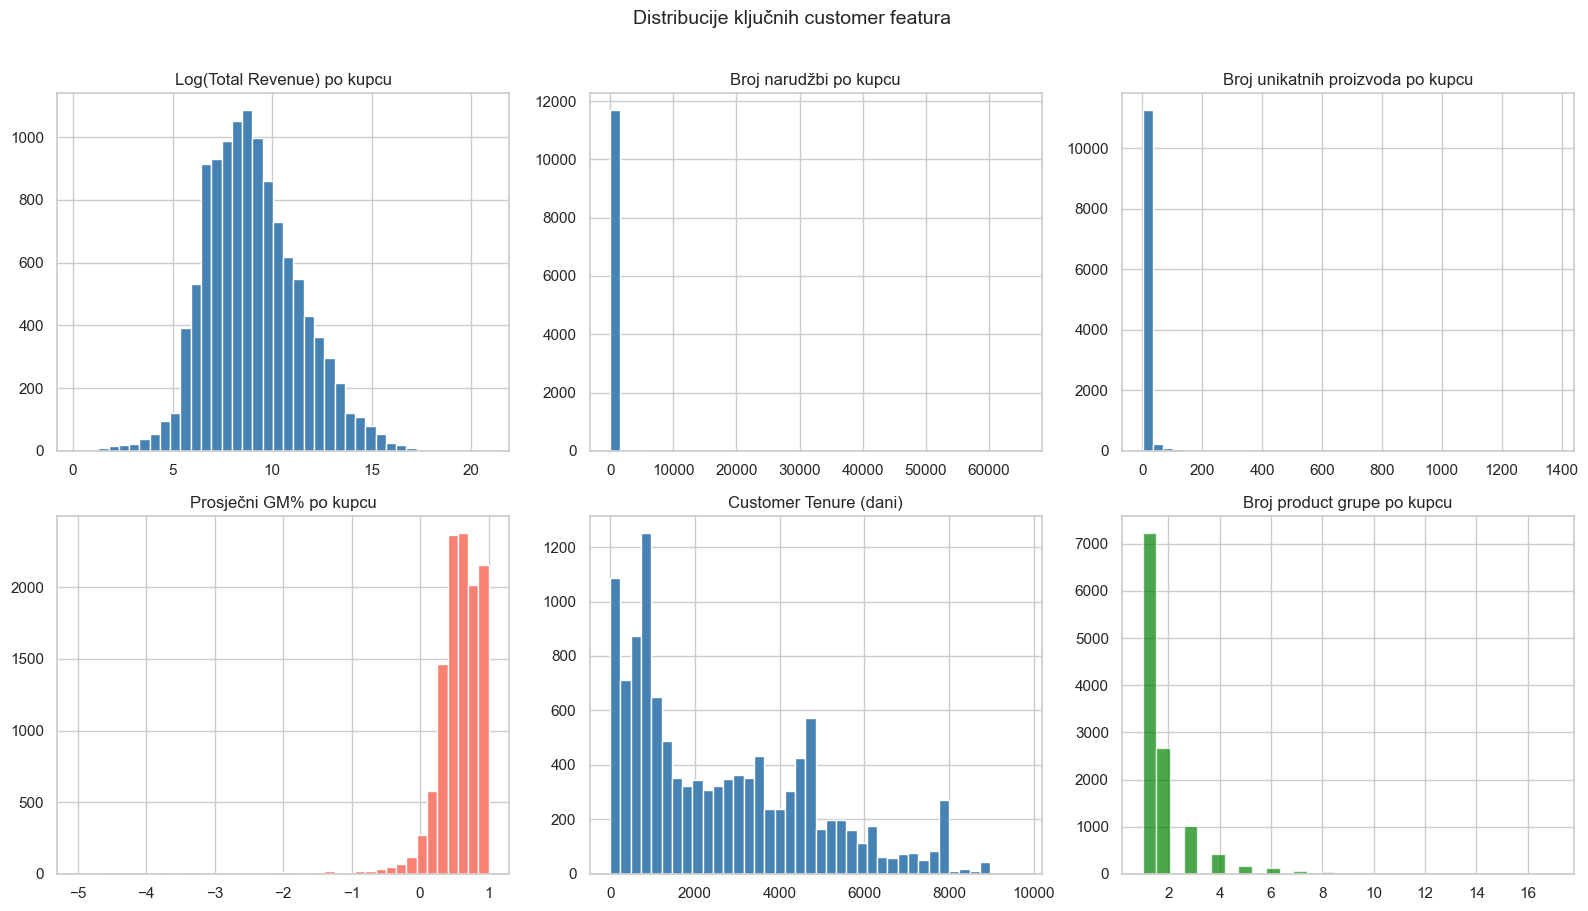

In [13]:
# 7f. Vizualizacija distribucija ključnih featura
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

customer_agg['total_revenue'].apply(lambda x: np.log1p(x)).hist(
    bins=40, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Log(Total Revenue) po kupcu')

customer_agg['total_orders'].hist(bins=40, ax=axes[0,1], color='steelblue')
axes[0,1].set_title('Broj narudžbi po kupcu')

customer_agg['total_items'].hist(bins=40, ax=axes[0,2], color='steelblue')
axes[0,2].set_title('Broj unikatnih proizvoda po kupcu')

customer_agg['avg_gm'].hist(bins=40, ax=axes[1,0], color='salmon')
axes[1,0].set_title('Prosječni GM% po kupcu')

customer_agg['customer_tenure_days'].hist(bins=40, ax=axes[1,1], color='steelblue')
axes[1,1].set_title('Customer Tenure (dani)')

customer_agg['n_product_groups'].hist(bins=30, ax=axes[1,2], color='green', alpha=0.7)
axes[1,2].set_title('Broj product grupe po kupcu')

plt.suptitle('Distribucije ključnih customer featura', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [14]:
# 7g. Product co-occurrence matrica (osnova za cross-sell)
# Grupiraj po Invoice # — koji proizvodi se pojavljuju na istoj fakturi?
invoice_items = df_encoded.groupby('Invoice #')['Product group'].apply(
    lambda x: list(x.dropna().unique())
).reset_index()
invoice_items.columns = ['invoice_id', 'product_groups']

# Filtriraj fakture s više od jednog produkta (cross-sell prilike)
multi_product = invoice_items[invoice_items['product_groups'].apply(len) > 1]
print(f'Fakture s 1 produktom: {(invoice_items["product_groups"].apply(len) == 1).sum():,}')
print(f'Fakture s 2+ produkata: {len(multi_product):,}')
print(f'% multi-product faktura: {len(multi_product)/len(invoice_items)*100:.1f}%')
display(multi_product.head(5))

Fakture s 1 produktom: 796,012
Fakture s 2+ produkata: 13,882
% multi-product faktura: 1.7%


,invoice_id,product_groups
0,99,"[Unknown, SF002]"
1,100,"[Unknown, SF002]"
2,101,"[Unknown, SF002]"
3,102,"[SF002, Unknown]"
4,103,"[SF002, Unknown]"


---
## 8. Korelacijska analiza numeričkih featura

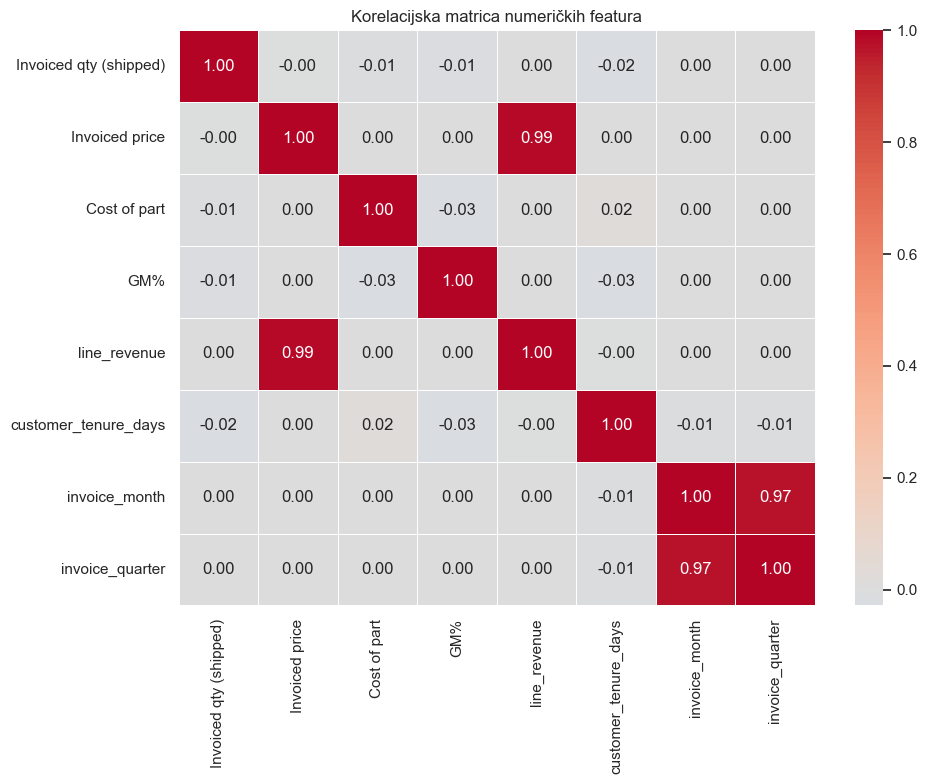

In [15]:
num_features = [
    'Invoiced qty (shipped)', 'Invoiced price', 'Cost of part',
    'GM%', 'line_revenue', 'customer_tenure_days',
    'invoice_month', 'invoice_quarter'
]

existing_num = [c for c in num_features if c in df_encoded.columns]
corr = df_encoded[existing_num].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Korelacijska matrica numeričkih featura')
plt.tight_layout()
plt.show()

---
## 9. Finalni dataset — spremi za modeliranje

In [16]:
# Finalni pregled
print('=== FINALNI DATASET ===')
print(f'Shape: {df_encoded.shape}')
print(f'Nullovi: {df_encoded.isnull().sum().sum()}')
print(f'\nStupci:')
for col in df_encoded.columns:
    print(f'  {col}: {df_encoded[col].dtype}')

=== FINALNI DATASET ===
Shape: (928762, 62)
Nullovi: 82513

Stupci:
  Manufacturing Region: object
  Manufacturing Location Code: object
  Intercompany: object
  CustomerID: int64
  Customer industry: object
  Customer Region: object
  Customer First Invoice Date: datetime64[ns]
  Top Customer Group: object
  Item Code: object
  Product family: object
  Product group: object
  Make vs Buy: object
  Sales Channel - Internal: object
  Sales Channel - External: object
  Invoice Date: datetime64[ns]
  Invoice #: int64
  Invoiced qty (shipped): float64
  Ordered qty: float64
  Invoiced price: float64
  Invoiced price (TX): float64
  Cost of part: float64
  GM%: float64
  CustomerID_enc: int64
  Item Code_enc: int64
  Manufacturing Location Code_enc: int64
  Sales Channel - Internal_enc: int64
  Sales Channel - External_enc: int64
  Top Customer Group_enc: int64
  Make vs Buy_enc: int64
  Manufacturing Region_Asia: bool
  Manufacturing Region_Europe: bool
  Manufacturing Region_North America

In [17]:
df_encoded.isnull().sum()[df_encoded.isnull().sum() > 0]

Ordered qty          23170
Cost of part         19781
GM%                  19781
line_gross_profit    19781
dtype: int64

In [18]:
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)
print(f'Converted {len(bool_cols)} bool columns to int ✓')

Converted 26 bool columns to int ✓


In [19]:
# Spremi očišćeni dataset
df_encoded.to_csv('../data/processed/data_clean_enc_fe.csv', index=False)
customer_agg.to_csv('../data/processed/customer_features.csv', index=False)
invoice_items.to_csv('../data/processed/invoice_items.csv', index=False)

print('Spremljeno ✓')
print('  → data/processed/data_clean_enc_fe.csv')
print('  → data/processed/customer_features.csv')
print('  → data/processed/invoice_items.csv')

Spremljeno ✓
  → data/processed/data_clean_enc_fe.csv
  → data/processed/customer_features.csv
  → data/processed/invoice_items.csv


---
## Sažetak — što smo napravili

| Korak | Akcija |
|-------|--------|
| Enkodiranje | Label encoding za visoko-kardinalne, OHE za nisko-kardinalne |
| Novi featuri | Tenure, revenue, gross profit, vremenski featuri |
| Agregati | Customer-level tablica za segmentaciju |
| Co-occurrence | Invoice-items tablica za market basket analysis |